# Student Performance Prediction System

This notebook organizes the existing project pipeline for Google Colab. It predicts the final student grade (`G3`, on a 0–20 scale) using the original dataset, preprocessing, and four regression models from `pipeline.py`.

**Run all cells from top to bottom.** The default dataset is the UCI Mathematics (`student-mat.csv`) file, which uses semicolon separators.


## Project overview

The existing project contains a Streamlit dashboard (`app.py`) and a reusable machine learning pipeline (`pipeline.py`). This notebook brings the pipeline into ordered cells for Colab. It keeps the original 80/20 split (`random_state=42`), imputers, scaling, one-hot encoding, model settings, five-fold R² cross-validation, and grade clipping.

The existing pipeline uses every available feature other than `G3`; there is no separate feature-selection algorithm in the original code.


## 1. Install and import dependencies

Colab usually includes these packages; this cell ensures the pipeline dependencies are available. Streamlit is only needed for the original local dashboard and is not required in this notebook.


In [ ]:
%pip -q install numpy pandas matplotlib scikit-learn joblib

import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

TARGET = "G3"  # final grade (0-20)
OUT, MODELS = "outputs", "models"
os.makedirs(OUT, exist_ok=True)


## 2. Load the dataset

For the simplest Colab workflow, upload `student-mat.csv` when prompted. If you upload a differently named CSV, the first CSV selected is used. Alternatively, place the dataset in a `data/` folder beside the notebook in Colab. The original UCI file is semicolon-separated.


In [ ]:
from google.colab import files
import os

uploaded = files.upload()  # Apne project ke data folder se student-mat.csv select karo

filename = next(
    (name for name in uploaded if os.path.basename(name).lower() == "student-mat.csv"),
    None
)

if filename is None:
    raise ValueError("student-mat.csv upload karo; galat CSV select hui hai.")

DATA_PATH = os.path.join("/content", filename)
print("Selected dataset:", DATA_PATH)

Saving student-mat.csv to student-mat.csv
Selected dataset: /content/student-mat.csv


## 3. Data loading and preprocessing

These functions follow the existing pipeline: load semicolon-delimited data with a comma-separated fallback, remove duplicates, trim column/value whitespace, and discard rows without the target. The model preprocessor imputes/scales numeric features and imputes/one-hot encodes categorical features.


In [ ]:
def load_data(path):
    """UCI files are ';' separated."""
    df = pd.read_csv(path, sep=";")
    if df.shape[1] == 1:  # fallback if comma separated
        df = pd.read_csv(path)
    return df


def clean(df):
    df = df.copy()
    df = df.drop_duplicates()
    df.columns = df.columns.str.strip()
    for c in df.select_dtypes("object"):
        df[c] = df[c].astype(str).str.strip().replace({"nan": np.nan, "": np.nan})
    if TARGET not in df.columns:
        raise ValueError(
            f"Dataset mein '{TARGET}' column nahi mila. "
            f"Available columns: {df.columns.tolist()}"
        )
    df = df.dropna(subset=[TARGET])  # target must exist
    return df


df = clean(load_data(DATA_PATH))
print("Loaded data shape:", df.shape)
display(df.head())


Loaded data shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


## 4. Exploratory data analysis (EDA)

Summarize the target and key inputs, then recreate the original EDA overview and correlation heatmap.


Shape: (395, 33)
Missing values:
 Series([], dtype: int64)


,G3,G1,G2,studytime,absences
count,395.00,395.00,395.00,395.00,395.00
mean,10.42,10.91,10.71,2.04,5.71
std,4.58,3.32,3.76,0.84,8.00
min,0.00,3.00,0.00,1.00,0.00
25%,8.00,8.00,9.00,1.00,0.00
50%,11.00,11.00,11.00,2.00,4.00
75%,14.00,13.00,13.00,2.00,8.00
max,20.00,19.00,19.00,4.00,75.00


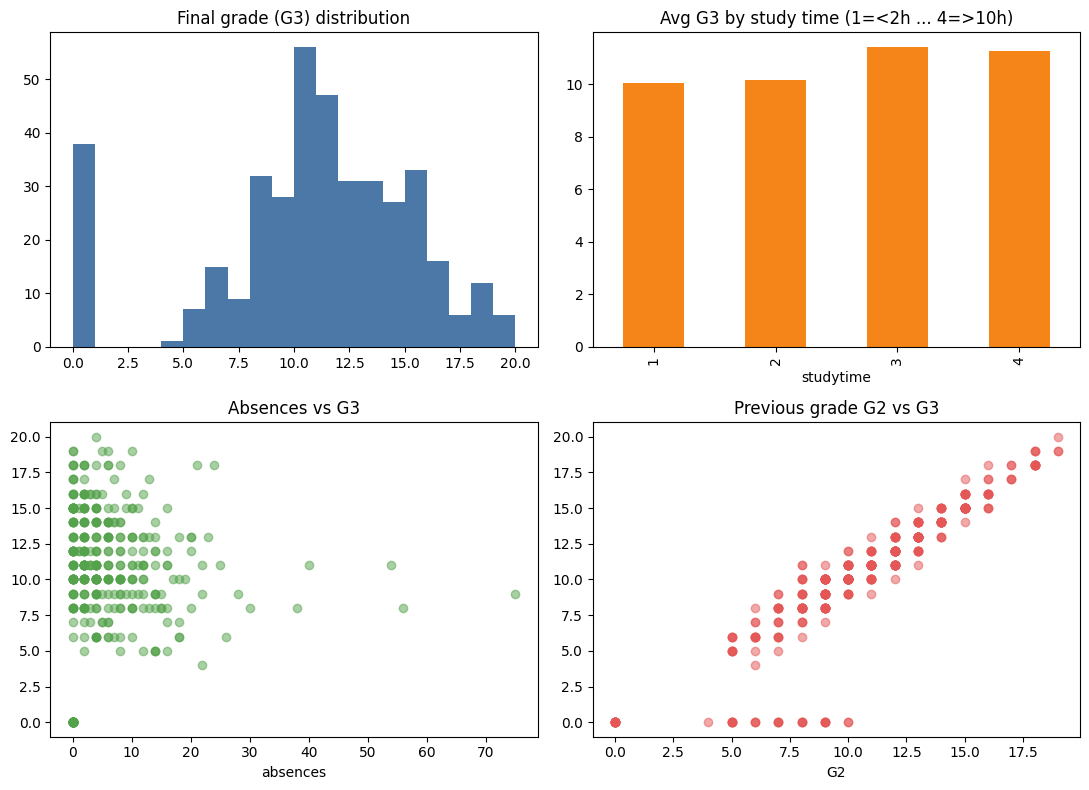

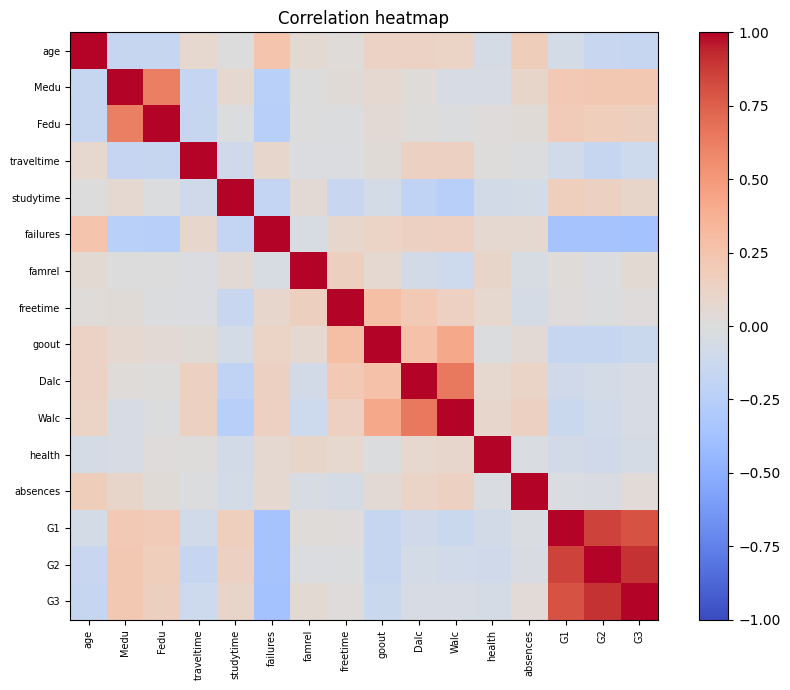

Top correlations with G3:
 G2          0.905
G1          0.801
failures   -0.360
Medu        0.217
age        -0.162
Fedu        0.152
Name: G3, dtype: float64


In [ ]:
print("Shape:", df.shape)
print("Missing values:\n", df.isna().sum()[df.isna().sum() > 0])
display(df[[TARGET, "G1", "G2", "studytime", "absences"]].describe().round(2))

fig, ax = plt.subplots(2, 2, figsize=(11, 8))
ax[0, 0].hist(df[TARGET], bins=20, color="#4C78A8")
ax[0, 0].set_title("Final grade (G3) distribution")
df.groupby("studytime")[TARGET].mean().plot.bar(ax=ax[0, 1], color="#F58518")
ax[0, 1].set_title("Avg G3 by study time (1=<2h ... 4=>10h)")
ax[1, 0].scatter(df["absences"], df[TARGET], alpha=.5, color="#54A24B")
ax[1, 0].set_title("Absences vs G3")
ax[1, 0].set_xlabel("absences")
ax[1, 1].scatter(df["G2"], df[TARGET], alpha=.5, color="#E45756")
ax[1, 1].set_title("Previous grade G2 vs G3")
ax[1, 1].set_xlabel("G2")
plt.tight_layout()
plt.savefig(f"{OUT}/eda_overview.png", dpi=130)
plt.show()
plt.close()

corr = df.select_dtypes("number").corr()
plt.figure(figsize=(9, 7))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(corr)), corr.columns, rotation=90, fontsize=7)
plt.yticks(range(len(corr)), corr.columns, fontsize=7)
plt.title("Correlation heatmap")
plt.tight_layout()
plt.savefig(f"{OUT}/correlation_heatmap.png", dpi=130)
plt.show()
plt.close()
print("Top correlations with G3:\n", corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).head(6).round(3))


## 5. Feature selection and train/test split

The original pipeline selects predictors by taking all columns except `G3`. It then uses an 80/20 train/test split with a fixed seed.


In [ ]:
X, y = df.drop(columns=[TARGET]), df[TARGET]
feature_columns = X.columns.tolist()
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Features: {len(feature_columns)}")
print("Training rows:", len(Xtr), "| Test rows:", len(Xte))


Features: 32
Training rows: 316 | Test rows: 79


## 6. Model training and evaluation (RMSE and R²)

Train the original Linear Regression, Ridge, Random Forest, and Gradient Boosting models. Report test RMSE and R² plus mean five-fold cross-validation R².


In [ ]:
def build_preprocessor(X):
    num = X.select_dtypes("number").columns.tolist()
    cat = X.select_dtypes(exclude="number").columns.tolist()
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat),
    ])

models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=5.0),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}
rows, fitted = [], {}
for name, model in models.items():
    pipe = Pipeline([("prep", build_preprocessor(X)), ("model", model)])
    pipe.fit(Xtr, ytr)
    pred = np.clip(pipe.predict(Xte), 0, 20)
    rmse = float(np.sqrt(mean_squared_error(yte, pred)))
    r2 = float(r2_score(yte, pred))
    cv = cross_val_score(pipe, X, y, cv=5, scoring="r2").mean()
    rows.append({"Model": name, "RMSE": rmse, "R2": r2, "CV_R2": cv})
    fitted[name] = (pipe, pred)
    print(f"{name:20s} RMSE={rmse:.3f}  R2={r2:.3f}  CV R2={cv:.3f}")

results = pd.DataFrame(rows).sort_values("RMSE").round(4).reset_index(drop=True)
results.to_csv(f"{OUT}/model_comparison.csv", index=False)
display(results)


Linear Regression    RMSE=2.351  R2=0.730  CV R2=0.784
Ridge                RMSE=2.327  R2=0.736  CV R2=0.790
Random Forest        RMSE=2.011  R2=0.803  CV R2=0.834
Gradient Boosting    RMSE=1.977  R2=0.809  CV R2=0.824


,Model,RMSE,R2,CV_R2
0,Gradient Boosting,1.9766,0.8095,0.8242
1,Random Forest,2.0106,0.8029,0.8342
2,Ridge,2.3269,0.7359,0.7898
3,Linear Regression,2.3512,0.7304,0.7842


## 7. Best model and actual-versus-predicted plot

Choose the model with the lowest test RMSE, as in the original pipeline, and save the comparison plot and fitted model bundle.


Best model: Gradient Boosting


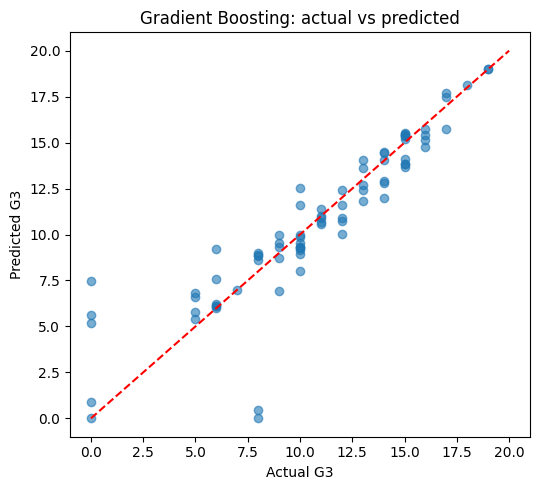

Saved model to models/best_model.joblib and evaluation outputs to outputs/


In [ ]:
best_model_name = results.iloc[0]["Model"]
best_pipeline, y_pred = fitted[best_model_name]
print("Best model:", best_model_name)

plt.figure(figsize=(5.5, 5))
plt.scatter(yte, y_pred, alpha=.6)
plt.plot([0, 20], [0, 20], "r--")
plt.xlabel("Actual G3")
plt.ylabel("Predicted G3")
plt.title(f"{best_model_name}: actual vs predicted")
plt.tight_layout()
plt.savefig(f"{OUT}/actual_vs_predicted.png", dpi=130)
plt.show()
plt.close()

import joblib
os.makedirs(MODELS, exist_ok=True)
joblib.dump({
    "pipeline": best_pipeline,
    "features": feature_columns,
    "best": best_model_name,
    "defaults": X.median(numeric_only=True).to_dict(),
    "cats": {c: sorted(X[c].dropna().unique().tolist()) for c in X.select_dtypes(exclude="number")},
}, f"{MODELS}/best_model.joblib")
print(f"Saved model to {MODELS}/best_model.joblib and evaluation outputs to {OUT}/")


## 8. Example prediction

Use the fitted best model to predict `G3` for one representative row from the test set. Predictions are clipped to the original 0–20 grade range.


In [ ]:
sample_input = Xte.iloc[[0]].copy()
sample_actual = float(yte.iloc[0])
sample_prediction = float(np.clip(best_pipeline.predict(sample_input)[0], 0, 20))
print("Actual G3:", sample_actual)
print("Predicted G3:", round(sample_prediction, 2))


Actual G3: 10.0
Predicted G3: 9.25


## 9. Conclusion

The notebook compares four regression models for predicting final grade `G3`. The results table reports test RMSE and R² alongside five-fold CV R²; the selected model is the one with the lowest test RMSE. The EDA figures, comparison CSV, and fitted model bundle are saved in `outputs/` and `models/` in the active Colab runtime.

**Colab submission steps:** upload this notebook to Google Drive, open it with Google Colaboratory, then use **Runtime → Run all**. When the dataset upload dialog appears, select `student-mat.csv` from the project’s `data/` folder. If you have only the project folder, upload the `student_performance` folder as a ZIP to your Drive, extract it in Colab, and update `DATA_PATH` in the dataset cell to the extracted `data/student-mat.csv` path.
